# Імпорт модулів

In [ ]:
import os
import pandas as pd
import numpy as np
import tensorflow as tf
import torch
from transformers import pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, f1_score
from sklearn.utils.class_weight import compute_class_weight
import seaborn as sns
import matplotlib.pyplot as plt
import shap
import nltk
import spacy
from nltk.corpus import stopwords
from gensim.models.doc2vec import Doc2Vec, TaggedDocument
from gensim.models import Word2Vec
from transformers import AutoTokenizer
from transformers import AutoModelForSequenceClassification
from datasets import Dataset
from tensorflow.keras.models import Model, Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout, Bidirectional, SpatialDropout1D
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.layers import (
    Input, Embedding, Conv1D, GlobalMaxPooling1D,
    Dense, Dropout, Concatenate
)
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras import regularizers

# Датасет

In [ ]:
import kagglehub

path = kagglehub.dataset_download("gandpablo/news-articles-for-political-bias-classification")

print("Path to dataset files: ", path)

Using Colab cache for faster access to the 'news-articles-for-political-bias-classification' dataset.
Path to dataset files:  /kaggle/input/news-articles-for-political-bias-classification


In [ ]:
df = pd.read_csv(os.path.join(path, 'bias_clean.csv'))

for col in df.columns:
  df[col] = df[col].astype('string')

df.head(10)

,url,topic,date,title,site,bias,page_text
0,https://www.npr.org/2021/01/01/952336030/what-...,general-news,2021-01-01,"What Got Us Through 2020? For Many, It Was Hob...",NPR (Online News),leaning-left,"What Got Us Through 2020? For Many, It Was Hob..."
1,https://www.cbsnews.com/news/new-years-eve-gat...,general-news,2020-12-31,New Year's Eve gatherings could accelerate COV...,CBS News (Online),leaning-left,New Year's Eve gatherings could accelerate COV...
2,https://nypost.com/2020/12/31/heres-how-countr...,general-news,2020-12-31,Here’s how countries around the world are ring...,New York Post (News),leaning-right,Here’s how countries around the world are ring...
3,https://www.theguardian.com/world/2020/dec/31/...,coronavirus,2020-12-31,Wisconsin health worker 'deliberately spoiled ...,The Guardian,left,Police in Wisconsin said on Thursday evening t...
4,https://www.foxnews.com/us/wis-hospital-intent...,coronavirus,2020-12-31,Wisconsin hospital employee 'intentionally' re...,Fox News Digital,right,A Wisconsin-based hospital on Wednesday said a...
5,https://www.newsmax.com/newsfront/bounties-int...,defense-and-security,2020-12-30,Trump to Declassify Intel China Paid for Attac...,Newsmax (News),right,President Donald Trump will be declassifying U...
6,https://www.npr.org/2020/12/30/951566925/censu...,politics,2020-12-30,Census To Miss Year-End Deadline For Deliverin...,NPR (Online News),leaning-left,Census Missed Year-End Deadline For Delivering...
7,https://nypost.com/2020/12/30/census-bureau-se...,politics,2020-12-30,Census Bureau set to blow year-end deadline on...,New York Post (News),leaning-right,The US Census Bureau is not expected to meet a...
8,https://www.foxnews.com/politics/josh-hawley-t...,politics,2020-12-30,Hawley says he'll object to Electoral College ...,Fox News Digital,right,"Sen. Josh Hawley, R-Mo., on Wednesday became t..."
9,https://apnews.com/article/election-2020-donal...,politics,2020-12-30,"Trump’s $2,000 checks stall in Senate as GOP b...",Associated Press,left,Trump push on $2K checks flops as GOP-led Sena...


In [ ]:
df['bias'] = df['bias'].replace({'leaning-left': 'left', 'leaning-right': 'right'})

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10832 entries, 0 to 10831
Data columns (total 7 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   url        10832 non-null  string
 1   topic      10832 non-null  string
 2   date       10832 non-null  string
 3   title      10832 non-null  string
 4   site       10832 non-null  string
 5   bias       10832 non-null  string
 6   page_text  10832 non-null  string
dtypes: string(7)
memory usage: 592.5 KB


<Axes: xlabel='bias'>

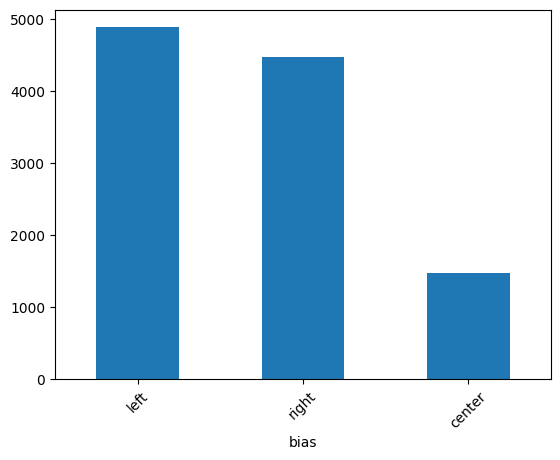

In [ ]:
df["bias"].value_counts().plot(kind='bar', rot=45)

In [ ]:
df["bias"].unique()

<StringArray>
['left', 'right', 'center']
Length: 3, dtype: string

In [ ]:
X = df["page_text"]

bias_mapping = {'left': 0, 'center': 1, 'right': 2}
y = df["bias"].map(bias_mapping)

In [ ]:
X.head()

,page_text
0,"What Got Us Through 2020? For Many, It Was Hob..."
1,New Year's Eve gatherings could accelerate COV...
2,Here’s how countries around the world are ring...
3,Police in Wisconsin said on Thursday evening t...
4,A Wisconsin-based hospital on Wednesday said a...


In [ ]:
y.head()

,bias
0,0
1,0
2,2
3,0
4,2


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Лематизація

In [ ]:
nlp = spacy.load("en_core_web_sm", disable=["parser", "ner"])

In [ ]:
def lemmatize(texts):
    processed_texts = []
    for doc in nlp.pipe(texts, n_process=-1, batch_size=100):
        lemmas = [t.lemma_ for t in doc if not t.is_stop and not t.is_punct and not t.is_space and t.is_alpha and len(t) > 2]
        processed_texts.append(" ".join(lemmas))
    return processed_texts

#X = X.apply(clean)
#X = X.apply(crop)
X_train_lem = pd.Series(lemmatize(X_train.tolist()))
X_test_lem = pd.Series(lemmatize(X_test.tolist()))

# TF-IDF

In [ ]:
nltk.download("stopwords")
stop_words = set(stopwords.words("english"))

more_words = {
    "cnn", "fox", "bbc", "msnbc", "nbc", "abc", "cbs", "npr",
    "reuters", "ap", "breitbart", "huffpost", "politico",
    "washingtonpost", "nytimes", "wsj", "guardian", "buzzfeed",
    "click", "get", "news", "read", "associated", "press",
    "apnews", "daily", "story", "report", "content", "mr", "ms", "mrs", "com",
    "examiner", "app", "https", "et", "say", "tell", "update", "recommend",
    "story", "follow", "load", "contribute", "pic", "twitter",
    "forbes", "usa", "today", "digital", "highlight", "key", "fact",
    "background", "topline", "additional", "even", "ny", "ca",
    "accord", "report", "meanwhile", "beast", "go",
    "criticise", "anonymity", "tx", "fl", "washington", "uk",
    "loading", "source", "speak", "reserve", "embed",
    "criticize", "like", "monday", "tuesday", "wednesday",
    "thursday", "friday", "saturday", "sunday", "writer",
    "spokesperson", "statement", "effort", "official",
    "familiar", "early", "month", "day", "year", "week"
}

custom_stop = list(stop_words | more_words)

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


In [ ]:
vectorizer = TfidfVectorizer(
    stop_words=custom_stop,
    max_features=15000,
    ngram_range=(1, 2),
    sublinear_tf=True,
    min_df=3
)

X_train_tfidf = vectorizer.fit_transform(X_train_lem)
X_test_tfidf  = vectorizer.transform(X_test_lem)

In [ ]:
model = LogisticRegression(
    class_weight="balanced",
    max_iter=2000,
)

model.fit(X_train_tfidf, y_train)

LogisticRegression(class_weight='balanced', max_iter=2000)

              precision    recall  f1-score   support

           0       0.67      0.63      0.65       976
           1       0.43      0.52      0.47       296
           2       0.68      0.68      0.68       895

    accuracy                           0.63      2167
   macro avg       0.59      0.61      0.60      2167
weighted avg       0.64      0.63      0.64      2167



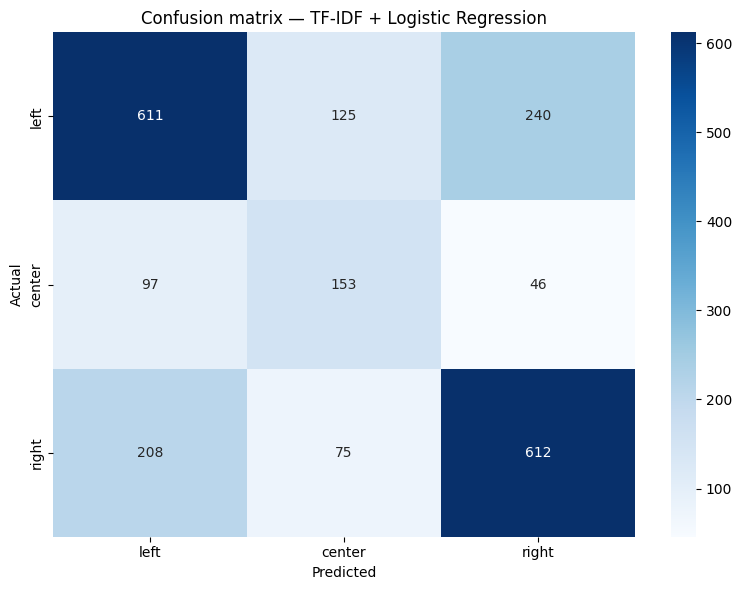

In [ ]:
y_pred = model.predict(X_test_tfidf)

print(classification_report(y_test, y_pred))

labels = ["left", "center", "right"]
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d",
            xticklabels=labels, yticklabels=labels,
            cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion matrix — TF-IDF + Logistic Regression")
plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=150)
plt.show()

In [ ]:
feature_names = vectorizer.get_feature_names_out()

for i, label in enumerate(model.classes_):
    top_idx = np.argsort(model.coef_[i])[-10:][::-1]
    top_words = [(feature_names[j], round(model.coef_[i][j], 3)) for j in top_idx]
    print(f"\nТоп слова для '{labels[label]}':")
    for word, weight in top_words:
        print(f"  {word}: {weight}")


Топ слова для 'left':
  interview: 1.445
  publicly: 1.351
  person: 1.274
  appear: 1.242
  far right: 1.212
  donald trump: 1.199
  donald: 1.179
  assault: 1.156
  democratic: 1.149
  repeatedly: 1.14

Топ слова для 'center':
  facts: 4.317
  defence: 3.724
  programme: 3.601
  tangent: 2.991
  reading: 2.922
  organisation: 2.862
  crucial quote: 2.428
  centre: 2.391
  quote: 1.996
  recognise: 1.93

Топ слова для 'right':
  president trump: 4.243
  left: 2.048
  illegal immigrant: 1.865
  president biden: 1.788
  illegal: 1.72
  biden: 1.677
  reveal: 1.65
  business: 1.6
  reportedly: 1.597
  terrorist: 1.488


In [ ]:
model = LinearSVC(class_weight='balanced', max_iter=2000)
model.fit(X_train_tfidf, y_train)

LinearSVC(class_weight='balanced', max_iter=2000)

              precision    recall  f1-score   support

           0       0.65      0.65      0.65       976
           1       0.51      0.44      0.47       296
           2       0.66      0.68      0.67       895

    accuracy                           0.64      2167
   macro avg       0.61      0.59      0.60      2167
weighted avg       0.63      0.64      0.63      2167



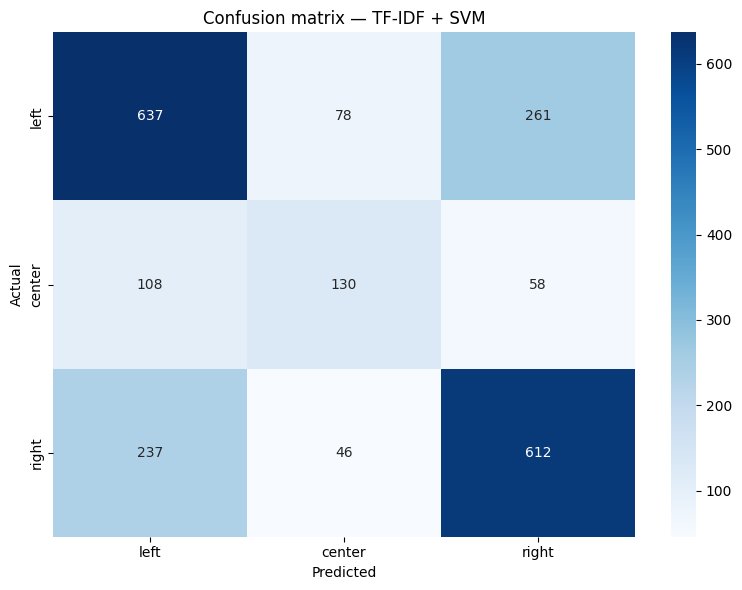

In [ ]:
y_pred = model.predict(X_test_tfidf)

print(classification_report(y_test, y_pred))

labels = ["left", "center", "right"]
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d",
            xticklabels=labels, yticklabels=labels,
            cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion matrix — TF-IDF + SVM")
plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=150)
plt.show()

In [ ]:
feature_names = vectorizer.get_feature_names_out()

for i, label in enumerate(model.classes_):
    top_idx = np.argsort(model.coef_[i])[-10:][::-1]
    top_words = [(feature_names[j], round(model.coef_[i][j], 3)) for j in top_idx]
    print(f"\nТоп слова для '{labels[label]}':")
    for word, weight in top_words:
        print(f"  {word}: {weight}")


Топ слова для 'left':
  far right: 2.017
  contributing: 1.956
  donald trump: 1.761
  survivor: 1.737
  donald: 1.728
  version: 1.715
  publicly: 1.711
  interview: 1.707
  defense department: 1.686
  insider: 1.579

Топ слова для 'center':
  facts: 5.952
  tangent: 4.031
  programme: 3.944
  defence: 3.941
  organisation: 3.491
  crucial quote: 3.266
  reading: 3.263
  recognise: 2.807
  centre: 2.708
  big number: 2.409

Топ слова для 'right':
  president trump: 5.027
  left: 2.782
  illegal immigrant: 2.599
  reportedly: 2.574
  reveal: 2.384
  doj: 2.181
  biden: 2.18
  admin: 2.107
  president biden: 2.087
  riot: 2.048


#Doc2Vec

In [ ]:
tagged_data = [TaggedDocument(words=text.split(), tags=[str(i)]) for i, text in enumerate(X_train_lem)]

model_d2v = Doc2Vec(
    vector_size=50,
    window=3,
    min_count=10,
    workers=4,
    epochs=100,
    dm=0
)

model_d2v.build_vocab(tagged_data)
model_d2v.train(tagged_data, total_examples=model_d2v.corpus_count, epochs=model_d2v.epochs)

In [ ]:
X_train_vec = np.array([model_d2v.dv[i] for i in range(len(X_train_lem))])
X_test_vec = np.array([model_d2v.infer_vector(text.split()) for text in X_test_lem])

In [ ]:
model = LogisticRegression(
    class_weight="balanced",
    max_iter=2000,
)

model.fit(X_train_vec, y_train)

LogisticRegression(class_weight='balanced', max_iter=2000)

              precision    recall  f1-score   support

           0       0.70      0.62      0.66       976
           1       0.35      0.58      0.44       296
           2       0.78      0.71      0.74       895

    accuracy                           0.65      2167
   macro avg       0.61      0.64      0.61      2167
weighted avg       0.69      0.65      0.66      2167



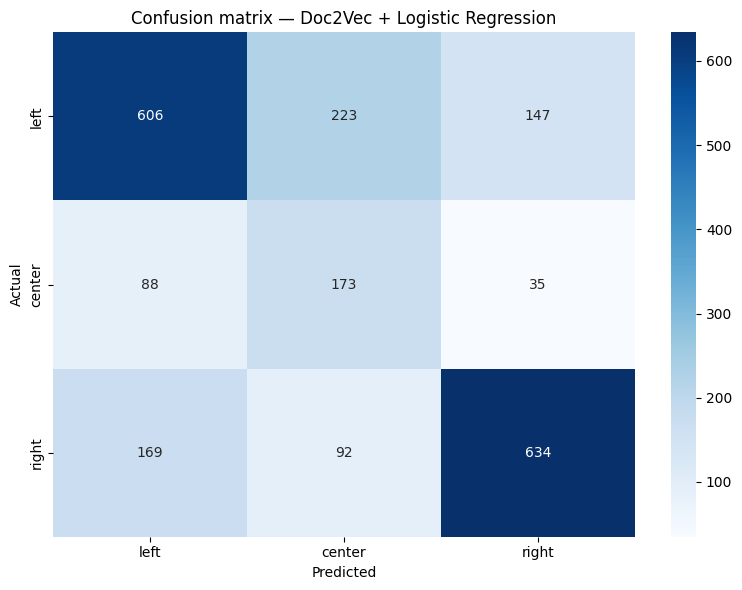

In [ ]:
y_pred = model.predict(X_test_vec)

print(classification_report(y_test, y_pred))

labels = ["left", "center", "right"]
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d",
            xticklabels=labels, yticklabels=labels,
            cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion matrix — Doc2Vec + Logistic Regression")
plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=150)
plt.show()

In [ ]:
model = LinearSVC(class_weight='balanced', max_iter=2000)
model.fit(X_train_vec, y_train)

LinearSVC(class_weight='balanced', max_iter=2000)

              precision    recall  f1-score   support

           0       0.67      0.75      0.71       976
           1       0.43      0.31      0.36       296
           2       0.75      0.73      0.74       895

    accuracy                           0.68      2167
   macro avg       0.62      0.60      0.60      2167
weighted avg       0.67      0.68      0.67      2167



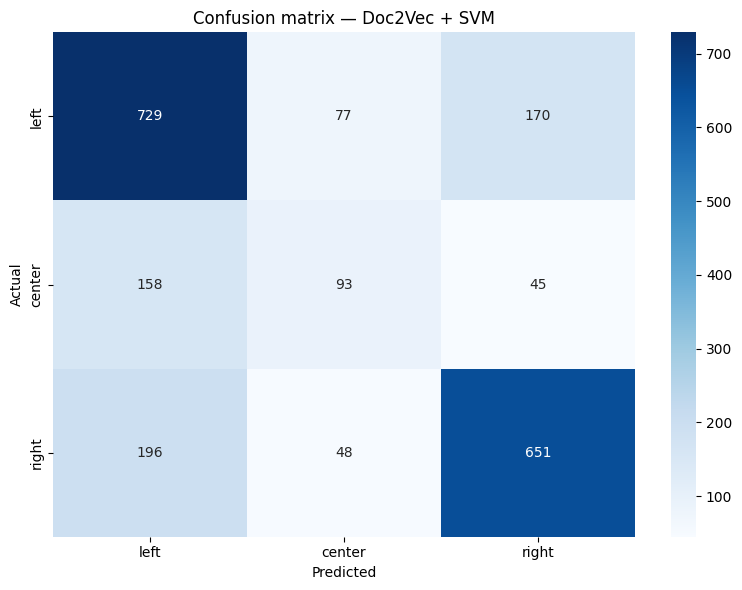

In [ ]:
y_pred = model.predict(X_test_vec)

print(classification_report(y_test, y_pred))

labels = ["left", "center", "right"]
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d",
            xticklabels=labels, yticklabels=labels,
            cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion matrix — Doc2Vec + SVM")
plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=150)
plt.show()

#Word2Vec

In [ ]:
train_sentences = [text.split() for text in X_train_lem]

model_w2v = Word2Vec(
    sentences=train_sentences,
    vector_size=100,
    window=5,
    min_count=5,
    workers=4,
    sg=1
)

In [ ]:
def get_sentence_vector(text, model, vector_size):
    words = text.split()
    word_vectors = [model.wv[word] for word in words if word in model.wv]

    if len(word_vectors) == 0:
        return np.zeros(vector_size)

    return np.mean(word_vectors, axis=0)

X_train_vec = np.array([get_sentence_vector(text, model_w2v, 100) for text in X_train_lem])
X_test_vec  = np.array([get_sentence_vector(text, model_w2v, 100) for text in X_test_lem])

In [ ]:
model = LogisticRegression(
    class_weight="balanced",
    max_iter=2000,
)

model.fit(X_train_vec, y_train)

LogisticRegression(class_weight='balanced', max_iter=2000)

              precision    recall  f1-score   support

           0       0.61      0.46      0.53       976
           1       0.23      0.50      0.31       296
           2       0.67      0.59      0.63       895

    accuracy                           0.52      2167
   macro avg       0.51      0.52      0.49      2167
weighted avg       0.59      0.52      0.54      2167



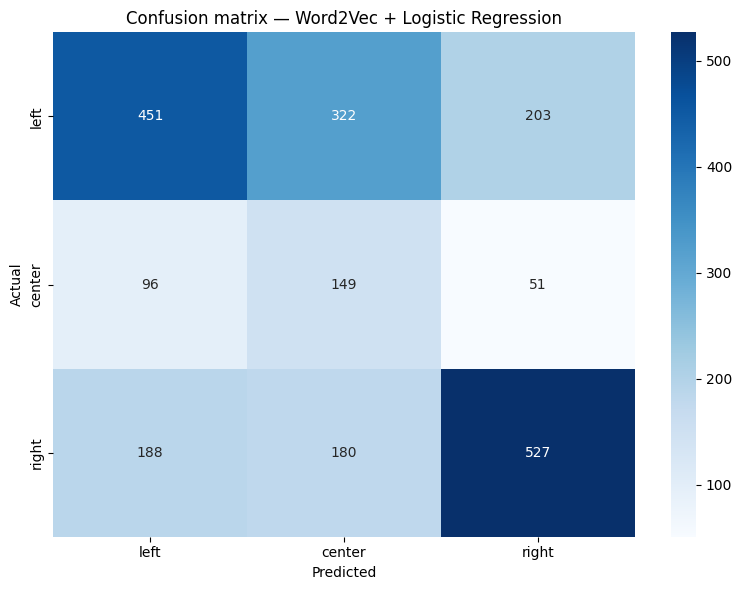

In [ ]:
y_pred = model.predict(X_test_vec)

print(classification_report(y_test, y_pred))

labels = ["left", "center", "right"]
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d",
            xticklabels=labels, yticklabels=labels,
            cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion matrix — Word2Vec + Logistic Regression")
plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=150)
plt.show()

In [ ]:
model = LinearSVC(class_weight='balanced', max_iter=2000)
model.fit(X_train_vec, y_train)

LinearSVC(class_weight='balanced', max_iter=2000)

              precision    recall  f1-score   support

           0       0.60      0.64      0.62       976
           1       0.26      0.24      0.25       296
           2       0.67      0.64      0.65       895

    accuracy                           0.58      2167
   macro avg       0.51      0.51      0.51      2167
weighted avg       0.58      0.58      0.58      2167



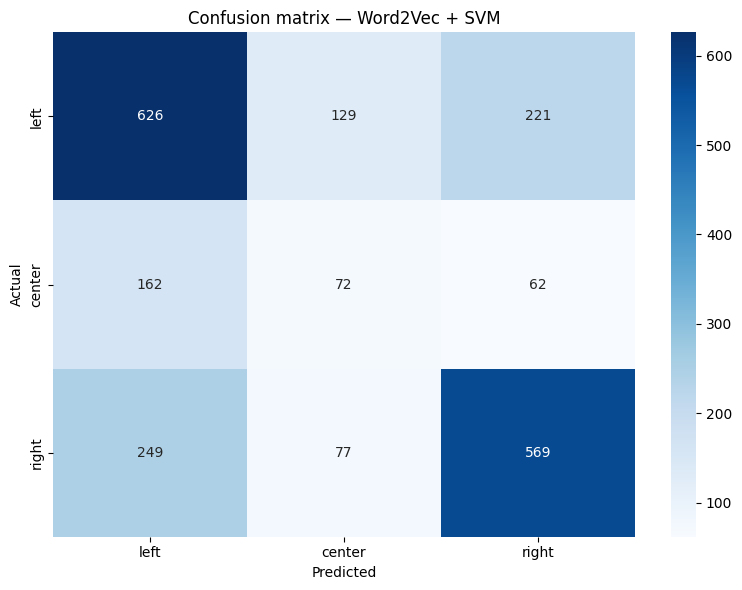

In [ ]:
y_pred = model.predict(X_test_vec)

print(classification_report(y_test, y_pred))

labels = ["left", "center", "right"]
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d",
            xticklabels=labels, yticklabels=labels,
            cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion matrix — Word2Vec + SVM")
plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=150)
plt.show()

#NN Tokenisation

In [ ]:
MAX_WORDS = 5000
MAX_LEN = 256

tokenizer = Tokenizer(num_words=MAX_WORDS, oov_token="<OOV>")
tokenizer.fit_on_texts(X_train)

X_train_nn = pad_sequences(tokenizer.texts_to_sequences(X_train), maxlen=MAX_LEN)
X_test_nn  = pad_sequences(tokenizer.texts_to_sequences(X_test),  maxlen=MAX_LEN)

In [ ]:
def get_leaderboard(model, X_data, target_class_idx, tokenizer, top_n=10, max_samples=50):
    reverse_word_map = {i: word for word, i in tokenizer.word_index.items()}
    word_importance = {}

    samples = X_data[:max_samples]

    for seq in samples:
        valid_indices = np.where(seq != 0)[0]
        if len(valid_indices) == 0: continue

        mutations = np.tile(seq, (len(valid_indices) + 1, 1))

        for i, idx_in_seq in enumerate(valid_indices):
            mutations[i + 1, idx_in_seq] = 0

        all_preds = model.predict(mutations, batch_size=len(mutations), verbose=0)[:, target_class_idx]

        base_pred = all_preds[0]
        reduced_preds = all_preds[1:]

        for i, idx_in_seq in enumerate(valid_indices):
            token = seq[idx_in_seq]
            word = reverse_word_map.get(token, "<OOV>").lower()
            if (word=="<oov>" or word in custom_stop or len(word) < 3 or not word.isalpha()):
                continue
            importance = base_pred - reduced_preds[i]
            word_importance[word] = word_importance.get(word, 0) + importance

    leaderboard = sorted(word_importance.items(), key=lambda x: x[1], reverse=True)
    return leaderboard[:top_n]

#LSTM

In [ ]:
model = Sequential([
    Embedding(MAX_WORDS, 100, input_length=MAX_LEN),
    SpatialDropout1D(0.4),
    Bidirectional(LSTM(16)),
    Dropout(0.5),
    Dense(5, activation="softmax")
])

model.compile(
    optimizer=Adam(learning_rate=0.0005),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.build((None, MAX_LEN))
model.summary()

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_2 (Embedding)         │ (None, 256, 100)       │       500,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ spatial_dropout1d_1             │ (None, 256, 100)       │             0 │
│ (SpatialDropout1D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_1 (Bidirectional) │ (None, 32)             │        14,976 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 5)              │           165 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 515,141 (1.97 MB)

 Trainable params: 515,141 (1.97 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
weights = compute_class_weight("balanced", classes=np.unique(y_train), y=y_train)
class_weight_dict = dict(enumerate(weights))

early_stop = EarlyStopping(
    monitor='val_loss',
    patience=2,
    restore_best_weights=True
)

history = model.fit(
    X_train_nn, y_train,
    epochs=10,
    batch_size=32,
    validation_split=0.1,
    class_weight=class_weight_dict,
    callbacks=[early_stop]
)

Epoch 1/10
244/244 ━━━━━━━━━━━━━━━━━━━━ 11s 29ms/step - accuracy: 0.3689 - loss: 1.2417 - val_accuracy: 0.4498 - val_loss: 1.0288
Epoch 2/10
244/244 ━━━━━━━━━━━━━━━━━━━━ 6s 25ms/step - accuracy: 0.4849 - loss: 1.0086 - val_accuracy: 0.5444 - val_loss: 0.9022
Epoch 3/10
244/244 ━━━━━━━━━━━━━━━━━━━━ 5s 22ms/step - accuracy: 0.5491 - loss: 0.9501 - val_accuracy: 0.5421 - val_loss: 0.9061
Epoch 4/10
244/244 ━━━━━━━━━━━━━━━━━━━━ 6s 26ms/step - accuracy: 0.6376 - loss: 0.8025 - val_accuracy: 0.6032 - val_loss: 0.8159
Epoch 5/10
244/244 ━━━━━━━━━━━━━━━━━━━━ 5s 22ms/step - accuracy: 0.7011 - loss: 0.6986 - val_accuracy: 0.6505 - val_loss: 0.7591
Epoch 6/10
244/244 ━━━━━━━━━━━━━━━━━━━━ 6s 24ms/step - accuracy: 0.7537 - loss: 0.6099 - val_accuracy: 0.6205 - val_loss: 0.8083
Epoch 7/10
244/244 ━━━━━━━━━━━━━━━━━━━━ 10s 22ms/step - accuracy: 0.8049 - loss: 0.5086 - val_accuracy: 0.6667 - val_loss: 0.7701


68/68 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step
              precision    recall  f1-score   support

           0       0.72      0.63      0.67       976
           1       0.35      0.62      0.44       296
           2       0.81      0.70      0.75       895

    accuracy                           0.66      2167
   macro avg       0.62      0.65      0.62      2167
weighted avg       0.70      0.66      0.67      2167



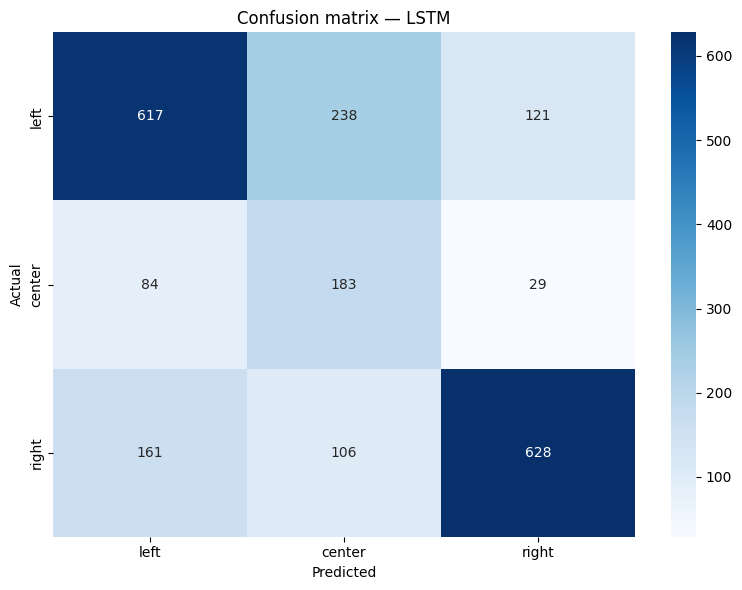

In [ ]:
y_pred = np.argmax(model.predict(X_test_nn), axis=1)

print(classification_report(y_test, y_pred))

labels = ["left", "center", "right"]
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d",
            xticklabels=labels, yticklabels=labels,
            cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion matrix — LSTM")
plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=150)
plt.show()

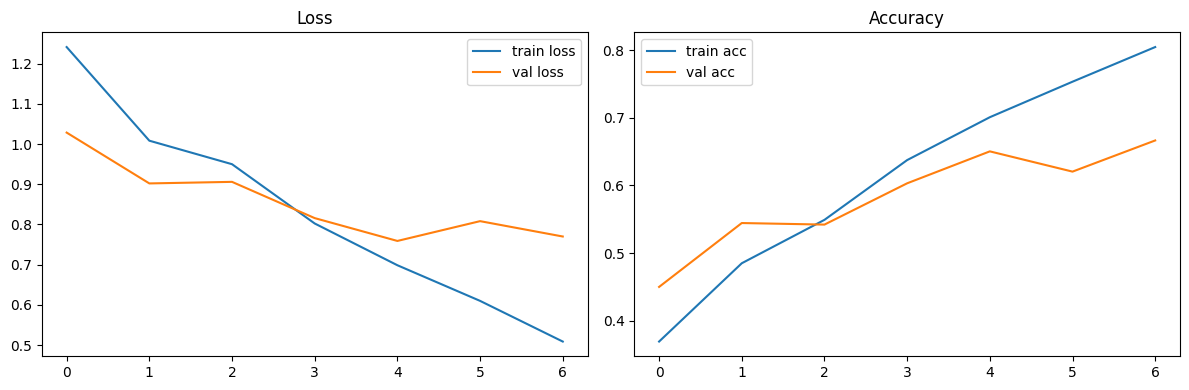

In [ ]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

ax1.plot(history.history["loss"],     label="train loss")
ax1.plot(history.history["val_loss"], label="val loss")
ax1.set_title("Loss"); ax1.legend()

ax2.plot(history.history["accuracy"],     label="train acc")
ax2.plot(history.history["val_accuracy"], label="val acc")
ax2.set_title("Accuracy"); ax2.legend()

plt.tight_layout()
plt.savefig("lstm_training.png", dpi=150)
plt.show()

In [ ]:
for i, label in enumerate(labels):
    class_data = X_test_nn[y_pred == i]
    if len(class_data) == 0: continue

    top_words = get_leaderboard(model, class_data, i, tokenizer)
    print(f"\nТоп слова для класу '{label}':")
    for word, score in top_words:
        print(f"  {word}: {score:.4f}")


Топ слова для класу 'left':
  independence: 0.8559
  course: 0.8443
  said: 0.7594
  rosenstein: 0.6969
  white: 0.6966
  contributed: 0.6548
  house: 0.6456
  writers: 0.5869
  donald: 0.5866
  became: 0.5818

Топ слова для класу 'center':
  last: 1.0565
  would: 0.9793
  said: 0.8535
  president: 0.8450
  signed: 0.8347
  republican: 0.7739
  russian: 0.7488
  one: 0.7479
  leader: 0.6628
  next: 0.6461

Топ слова для класу 'right':
  purposes: 0.0534
  claims: 0.0461
  business: 0.0371
  deliver: 0.0338
  hillary: 0.0330
  gay: 0.0314
  recommended: 0.0298
  participate: 0.0293
  brings: 0.0135
  filibuster: 0.0119


#TextCNN

In [ ]:
def build_textcnn(vocab_size, embed_dim, max_len, num_classes,
                  filter_sizes=(2, 3, 4), num_filters=32):

    inputs = Input(shape=(max_len,))

    x = Embedding(vocab_size, embed_dim, input_length=max_len)(inputs)

    branches = []
    for fs in filter_sizes:
        conv = Conv1D(filters=num_filters,
                      kernel_size=fs,
                      activation="relu",
                      padding="valid",
                      kernel_regularizer=regularizers.l2(0.01))(x)
        pool = GlobalMaxPooling1D()(conv)
        branches.append(pool)

    concat = Concatenate()(branches)
    drop   = Dropout(0.5)(concat)
    out    = Dense(num_classes, activation="softmax")(drop)

    return Model(inputs=inputs, outputs=out)

In [ ]:
EMBED_DIM = 100

model = build_textcnn(
    vocab_size=MAX_WORDS,
    embed_dim=EMBED_DIM,
    max_len=MAX_LEN,
    num_classes=5
)

model.compile(
    optimizer=Adam(learning_rate=0.0005),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "functional_3"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_3       │ (None, 256)       │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding_3         │ (None, 256, 100)  │    500,000 │ input_layer_3[0]… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_3 (Conv1D)   │ (None, 255, 32)   │      6,432 │ embedding_3[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_4 (Conv1D)   │ (None, 254, 32)   │      9,632 │ embedding_3[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1d_5 (Conv1D)   │ (None, 253, 32)   │     12,832 │ embedding_3[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_max_pooling… │ (None, 32)        │          0 │ conv1d_3[0][0]    │
│ (GlobalMaxPooling1… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_max_pooling… │ (None, 32)        │          0 │ conv1d_4[0][0]    │
│ (GlobalMaxPooling1… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_max_pooling… │ (None, 32)        │          0 │ conv1d_5[0][0]    │
│ (GlobalMaxPooling1… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_1       │ (None, 96)        │          0 │ global_max_pooli… │
│ (Concatenate)       │                   │            │ global_max_pooli… │
│                     │                   │            │ global_max_pooli… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_3 (Dropout) │ (None, 96)        │          0 │ concatenate_1[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_3 (Dense)     │ (None, 5)         │        485 │ dropout_3[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 529,381 (2.02 MB)

 Trainable params: 529,381 (2.02 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
weights = compute_class_weight("balanced", classes=np.unique(y_train), y=y_train)
class_weight_dict = dict(enumerate(weights))

early_stop = EarlyStopping(
    monitor='val_loss',
    patience=2,
    restore_best_weights=True
)

history = model.fit(
    X_train_nn, y_train,
    epochs=10,
    batch_size=32,
    validation_split=0.15,
    class_weight=class_weight_dict,
    callbacks=[early_stop]
)

Epoch 1/10
231/231 ━━━━━━━━━━━━━━━━━━━━ 17s 42ms/step - accuracy: 0.4223 - loss: 1.7798 - val_accuracy: 0.4892 - val_loss: 1.1281
Epoch 2/10
231/231 ━━━━━━━━━━━━━━━━━━━━ 3s 12ms/step - accuracy: 0.5329 - loss: 1.0379 - val_accuracy: 0.6446 - val_loss: 0.8886
Epoch 3/10
231/231 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - accuracy: 0.6073 - loss: 0.8979 - val_accuracy: 0.6731 - val_loss: 0.8053
Epoch 4/10
231/231 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.6600 - loss: 0.8189 - val_accuracy: 0.7154 - val_loss: 0.7501
Epoch 5/10
231/231 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.6735 - loss: 0.7843 - val_accuracy: 0.7162 - val_loss: 0.7554
Epoch 6/10
231/231 ━━━━━━━━━━━━━━━━━━━━ 4s 18ms/step - accuracy: 0.7048 - loss: 0.7376 - val_accuracy: 0.7092 - val_loss: 0.7524


68/68 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step
              precision    recall  f1-score   support

           0       0.73      0.75      0.74       976
           1       0.41      0.58      0.48       296
           2       0.87      0.73      0.79       895

    accuracy                           0.72      2167
   macro avg       0.67      0.68      0.67      2167
weighted avg       0.74      0.72      0.72      2167



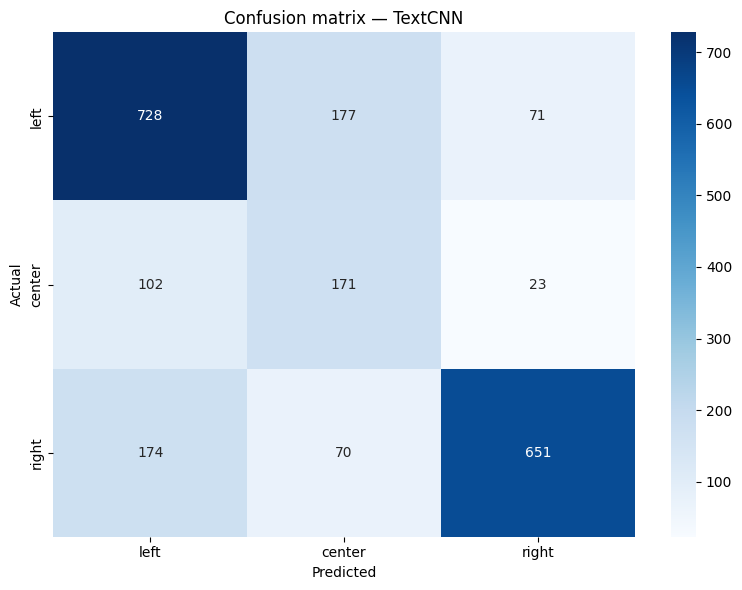

In [ ]:
y_pred = np.argmax(model.predict(X_test_nn), axis=1)

print(classification_report(y_test, y_pred))
labels = ["left", "center", "right"]
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d",
            xticklabels=labels, yticklabels=labels,
            cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion matrix — TextCNN")
plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=150)
plt.show()

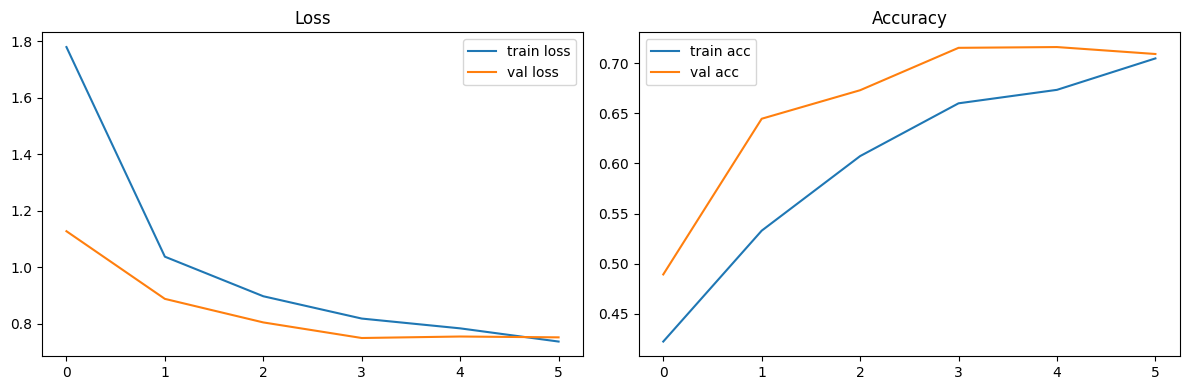

In [ ]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

ax1.plot(history.history["loss"],     label="train loss")
ax1.plot(history.history["val_loss"], label="val loss")
ax1.set_title("Loss"); ax1.legend()

ax2.plot(history.history["accuracy"],     label="train acc")
ax2.plot(history.history["val_accuracy"], label="val acc")
ax2.set_title("Accuracy"); ax2.legend()

plt.tight_layout()
plt.savefig("lstm_training.png", dpi=150)
plt.show()

In [ ]:
for i, label in enumerate(labels):
    class_data = X_test_nn[y_pred == i]
    if len(class_data) == 0: continue

    top_words = get_leaderboard(model, class_data, i, tokenizer)
    print(f"\nТоп слова для класу '{label}':")
    for word, score in top_words:
        print(f"  {word}: {score:.4f}")


Топ слова для класу 'left':
  said: 3.8523
  trump: 2.0909
  contributed: 1.4241
  house: 1.2320
  people: 1.1957
  would: 1.0856
  also: 0.8335
  president: 0.8015
  need: 0.7977
  national: 0.7787

Топ слова для класу 'center':
  said: 2.3738
  trump: 1.6267
  president: 1.0999
  also: 1.0576
  federal: 0.8574
  people: 0.8227
  would: 0.8154
  biden: 0.7337
  last: 0.6990
  one: 0.6948

Топ слова для класу 'right':
  clicking: 0.7009
  watched: 0.1643
  videos: 0.0203
  business: 0.0064
  passengers: 0.0047
  open: 0.0017
  interested: 0.0013
  votes: 0.0013
  scandal: 0.0011
  division: 0.0010


#BERT

In [ ]:
tokenizer = AutoTokenizer.from_pretrained("distilbert/distilbert-base-uncased-finetuned-sst-2-english")

def tokenize(batch):
    return tokenizer(batch["text"], truncation=True, padding="max_length", max_length=512)

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:93: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json:   0%|          | 0.00/629 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

In [ ]:
train_df = pd.DataFrame({"text": X_train, "labels": y_train})
test_df  = pd.DataFrame({"text": X_test, "labels": y_test})

train_ds = Dataset.from_pandas(train_df, preserve_index=False)
test_ds  = Dataset.from_pandas(test_df, preserve_index=False)

train_ds = train_ds.map(tokenize, batched=True)
test_ds  = test_ds.map(tokenize, batched=True)

Map:   0%|          | 0/8665 [00:00<?, ? examples/s]

Map:   0%|          | 0/2167 [00:00<?, ? examples/s]

In [ ]:
model = AutoModelForSequenceClassification.from_pretrained(
    "distilbert/distilbert-base-uncased-finetuned-sst-2-english",
    num_labels=3,
    id2label={0:"left", 1:"center", 2:"right"},
    label2id=bias_mapping,
    ignore_mismatched_sizes=True
)

model.safetensors:   0%|          | 0.00/268M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

DistilBertForSequenceClassification LOAD REPORT from: distilbert/distilbert-base-uncased-finetuned-sst-2-english
Key               | Status   |                                                                                     
------------------+----------+-------------------------------------------------------------------------------------
classifier.bias   | MISMATCH | Reinit due to size mismatch ckpt: torch.Size([2]) vs model:torch.Size([3])          
classifier.weight | MISMATCH | Reinit due to size mismatch ckpt: torch.Size([2, 768]) vs model:torch.Size([3, 768])

Notes:
- MISMATCH	:ckpt weights were loaded, but they did not match the original empty weight shapes.


In [ ]:
from transformers import TrainingArguments, Trainer
from sklearn.metrics import accuracy_score, f1_score
import numpy as np

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)
    return {
        "accuracy": accuracy_score(labels, preds),
        "f1_macro": f1_score(labels, preds, average="macro")
    }

training_args = TrainingArguments(
    output_dir="./bert-bias",
    num_train_epochs=3,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=32,
    eval_strategy="epoch",
    save_strategy="epoch",
    load_best_model_at_end=True,
    learning_rate=2e-5,
    weight_decay=0.01,
    logging_steps=50,
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_ds,
    eval_dataset=test_ds,
    compute_metrics=compute_metrics,
)

trainer.train()

Epoch,Training Loss,Validation Loss,Accuracy,F1 Macro
1,0.663754,0.633594,0.746193,0.713459
2,0.400222,0.574133,0.783572,0.755139
3,0.333241,0.572207,0.798339,0.770303


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

There were missing keys in the checkpoint model loaded: ['distilbert.embeddings.LayerNorm.weight', 'distilbert.embeddings.LayerNorm.bias'].
There were unexpected keys in the checkpoint model loaded: ['distilbert.embeddings.LayerNorm.beta', 'distilbert.embeddings.LayerNorm.gamma'].


TrainOutput(global_step=1626, training_loss=0.5384890848420203, metrics={'train_runtime': 1538.8914, 'train_samples_per_second': 16.892, 'train_steps_per_second': 1.057, 'total_flos': 3443551437818880.0, 'train_loss': 0.5384890848420203, 'epoch': 3.0})

              precision    recall  f1-score   support

        left       0.79      0.84      0.81       976
      center       0.78      0.61      0.68       296
       right       0.82      0.81      0.82       895

    accuracy                           0.80      2167
   macro avg       0.79      0.75      0.77      2167
weighted avg       0.80      0.80      0.80      2167



Text(0.5, 1.0, 'BERT confusion matrix')

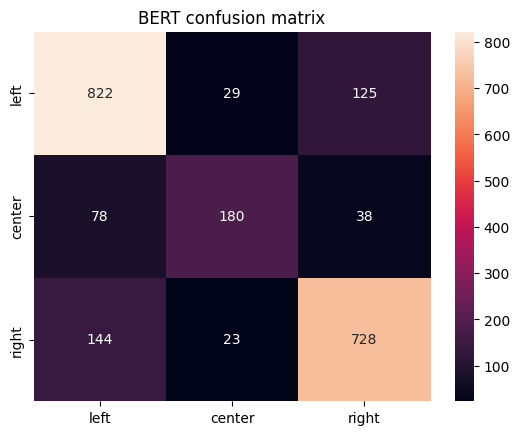

In [ ]:
preds_output = trainer.predict(test_ds)
preds = np.argmax(preds_output.predictions, axis=-1)
labels = preds_output.label_ids
id2label = {0:"left", 1:"center", 2:"right"}

print(classification_report(labels, preds, target_names=list(id2label.values())))

cm = confusion_matrix(labels, preds)
sns.heatmap(cm, annot=True, fmt="d",
            xticklabels=id2label.values(),
            yticklabels=id2label.values())
plt.title("BERT confusion matrix")

In [ ]:
import torch
import numpy as np
from tqdm import tqdm

def get_bert_leaderboard(model, tokenizer, texts, target_class_idx, top_n=10, max_samples=30):
    word_importance = {}
    model.eval()
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model.to(device)

    samples = texts[:max_samples]

    for text in samples:
        encoding = tokenizer(text, return_tensors='pt', truncation=True, padding=True, max_length=256)
        input_ids = encoding['input_ids'].to(device)
        attention_mask = encoding['attention_mask'].to(device)

        tokens = tokenizer.convert_ids_to_tokens(input_ids[0])

        with torch.no_grad():
            outputs = model(input_ids, attention_mask=attention_mask)
            base_pred = torch.softmax(outputs.logits, dim=1)[0][target_class_idx].item()

        special_tokens = [tokenizer.cls_token, tokenizer.sep_token, tokenizer.pad_token]

        for i, token in enumerate(tokens):
            if token in special_tokens or token.startswith("##"):
                continue

            masked_input_ids = input_ids.clone()
            masked_input_ids[0][i] = tokenizer.mask_token_id

            with torch.no_grad():
                outputs_masked = model(masked_input_ids, attention_mask=attention_mask)
                red_pred = torch.softmax(outputs_masked.logits, dim=1)[0][target_class_idx].item()

            importance = base_pred - red_pred

            clean_word = token.lower()
            if (clean_word in custom_stop or len(clean_word) < 3 or not clean_word.isalpha()):
                continue

            word_importance[clean_word] = word_importance.get(clean_word, 0) + importance

    leaderboard = sorted(word_importance.items(), key=lambda x: x[1], reverse=True)
    return leaderboard[:top_n]

In [ ]:
for i in range(len(id2label)):
    class_name = id2label[i]
    class_data = X_test[preds == i]
    if len(class_data) == 0: continue

    top_words = get_bert_leaderboard(model, tokenizer, class_data, i)
    print(f"\nТоп слова для класу '{class_name}':")
    for word, score in top_words:
        print(f"  {word}: {score:.4f}")


Топ слова для класу 'left':
  donald: 2.7832
  said: 1.8623
  trump: 1.6345
  people: 0.6506
  told: 0.6161
  caused: 0.5189
  epidemic: 0.4814
  adams: 0.4776
  public: 0.4566
  wallace: 0.4327

Топ слова для класу 'center':
  nhs: 0.4760
  updated: 0.4449
  analysis: 0.3138
  highlighted: 0.3130
  december: 0.3042
  latest: 0.2886
  people: 0.2579
  evidence: 0.2572
  data: 0.2482
  message: 0.2135

Топ слова для класу 'right':
  president: 1.1033
  first: 0.4436
  obama: 0.2907
  flynn: 0.2844
  border: 0.1821
  offered: 0.1667
  illegal: 0.1603
  officials: 0.1602
  general: 0.1572
  retired: 0.1556


#BART Zero-shot

In [ ]:
classifier = pipeline("zero-shot-classification",
                      model="valhalla/distilbart-mnli-12-1",
                      device=0 if torch.cuda.is_available() else -1)

Loading weights:   0%|          | 0/231 [00:00<?, ?it/s]

The tied weights mapping and config for this model specifies to tie model.shared.weight to model.decoder.embed_tokens.weight, but both are present in the checkpoints, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning
The tied weights mapping and config for this model specifies to tie model.shared.weight to model.encoder.embed_tokens.weight, but both are present in the checkpoints, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning


In [ ]:
test_input = X_test
test_labels = y_test

labels = ["left",  "center", "right"]
results = classifier(test_input.tolist(), labels, multi_label=False, batch_size=12)

label_to_idx = {label: i for i, label in enumerate(labels)}
predictions = [label_to_idx[res['labels'][0]] for res in results]

              precision    recall  f1-score   support

        left       0.51      0.45      0.48       976
      center       0.13      0.38      0.19       296
       right       0.41      0.19      0.26       895

    accuracy                           0.34      2167
   macro avg       0.35      0.34      0.31      2167
weighted avg       0.42      0.34      0.35      2167



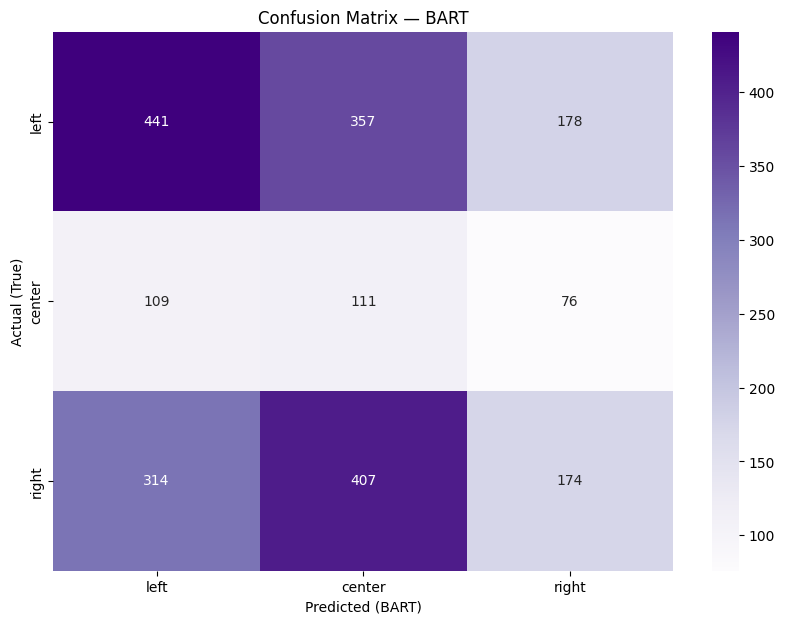

In [ ]:
# 1. Classification Report
print(classification_report(test_labels, predictions, target_names=labels))

# 2. Confusion Matrix
cm = confusion_matrix(test_labels, predictions)

plt.figure(figsize=(10, 7))
sns.heatmap(cm, annot=True, fmt='d', cmap='Purples',
            xticklabels=labels,
            yticklabels=labels)
plt.xlabel('Predicted (BART)')
plt.ylabel('Actual (True)')
plt.title('Confusion Matrix — BART')
plt.show()

In [ ]:
def get_bart_leaderboard(classifier, texts, target_label, top_n=10, max_samples=10):
    word_importance = {}
    samples = texts[:max_samples]
    INTERNAL_BATCH = 4

    for text in samples:
        words = text.split()
        if len(words) < 5: continue
        unique_words = [w for w in set(words) if w.lower().strip(".,!?:;\"'") not in custom_stop
                        and len(w.lower().strip(".,!?:;\"'")) >= 3
                        and w.lower().strip(".,!?:;\"'").isalpha()]
        if not unique_words: continue

        with torch.no_grad():
            base_res = classifier(text, candidate_labels=[target_label])
            base_score = base_res['scores'][0]

        reduced_scores = []
        mutations = [" ".join([w for w in words if w != target]) for target in unique_words]

        for i in range(0, len(mutations), INTERNAL_BATCH):
            batch = mutations[i:i + INTERNAL_BATCH]
            with torch.no_grad():
                batch_res = classifier(batch, candidate_labels=[target_label], batch_size=INTERNAL_BATCH)
                if isinstance(batch_res, dict): batch_res = [batch_res]
                reduced_scores.extend([r['scores'][0] for r in batch_res])

        for i, word in enumerate(unique_words):
            clean_word = word.lower().strip(".,!?:;\"'")
            importance = base_score - reduced_scores[i]
            word_importance[clean_word] = word_importance.get(clean_word, 0) + importance

    leaderboard = sorted(word_importance.items(), key=lambda x: x[1], reverse=True)
    return leaderboard[:top_n]

In [ ]:
for i, label_str in enumerate(labels):
    class_data_list = [text for text, pred_idx in zip(test_input, predictions) if pred_idx == i]
    if len(class_data_list) == 0: continue

    top_words = get_bart_leaderboard(classifier, class_data_list, label_str)
    print(f"\nТоп слова для класу '{label_str}':")
    for word, score in top_words:
        print(f"  {word}: {score:.4f}")

You seem to be using the pipelines sequentially on GPU. In order to maximize efficiency please use a dataset



Топ слова для класу 'left':
  voices: 0.4377
  censorship: 0.4222
  right: 0.4139
  guns: 0.3791
  police: 0.3471
  share: 0.3457
  prager: 0.3107
  facebook: 0.3026
  platforms: 0.2944
  tweets: 0.2871

Топ слова для класу 'center':
  elections: 0.5182
  party: 0.4123
  congress: 0.3747
  democrats: 0.3606
  pelosi: 0.3586
  house: 0.3539
  republicans: 0.3121
  play: 0.3077
  committee: 0.2790
  back: 0.2790

Топ слова для класу 'right':
  recession: 0.7479
  last: 0.6311
  layoffs: 0.5447
  one: 0.5348
  yet: 0.5244
  since: 0.4973
  far: 0.4831
  inflation: 0.4616
  said: 0.4495
  others: 0.4482


#BART Few-shot

In [ ]:
classifier = pipeline("zero-shot-classification",
                      model="valhalla/distilbart-mnli-12-1",
                      device=0 if torch.cuda.is_available() else -1)

Loading weights:   0%|          | 0/231 [00:00<?, ?it/s]

The tied weights mapping and config for this model specifies to tie model.shared.weight to model.decoder.embed_tokens.weight, but both are present in the checkpoints, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning
The tied weights mapping and config for this model specifies to tie model.shared.weight to model.encoder.embed_tokens.weight, but both are present in the checkpoints, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning


In [ ]:
few_shot_labels = [
    "left-wing political bias: progressive ideology, social equality, government intervention",
    "centrist political reporting: balanced, moderate, non-partisan",
    "right-wing political bias: conservative ideology, free market, traditional values"
]

custom_hypothesis = "This text reflects {} ideology."

In [ ]:
test_input = X_test
test_labels = y_test

labels = ["left", "center", "right"]
results = classifier(test_input.tolist(),
                     candidate_labels=few_shot_labels,
                     hypothesis_template=custom_hypothesis,
                     multi_label=False,
                     batch_size=12)

label_mapping = {label: i for i, label in enumerate(few_shot_labels)}
predictions = [label_mapping[res['labels'][0]] for res in results]

              precision    recall  f1-score   support

        left       0.49      0.36      0.41       976
      center       0.13      0.22      0.16       296
       right       0.40      0.42      0.41       895

    accuracy                           0.36      2167
   macro avg       0.34      0.33      0.33      2167
weighted avg       0.40      0.36      0.38      2167



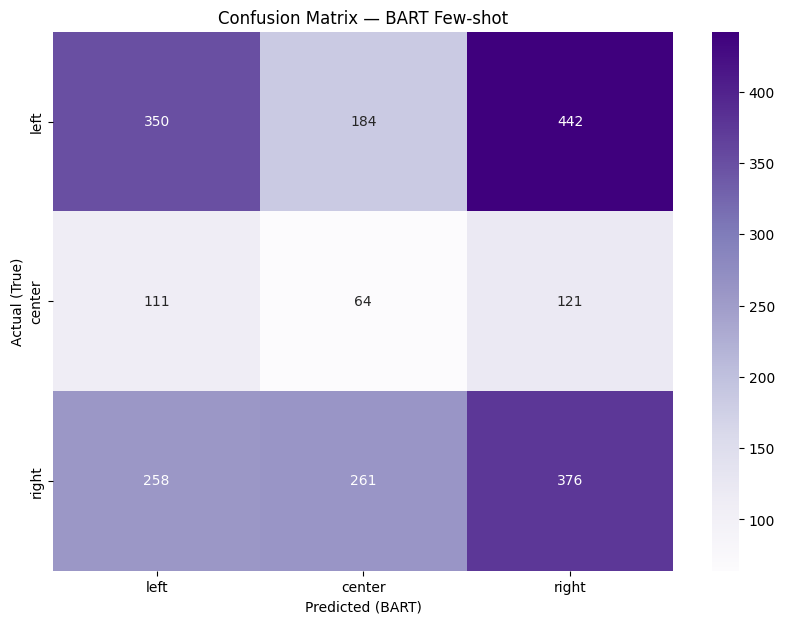

In [ ]:
print(classification_report(test_labels, predictions, target_names=labels))

cm = confusion_matrix(test_labels, predictions)

plt.figure(figsize=(10, 7))
sns.heatmap(cm, annot=True, fmt='d', cmap='Purples',
            xticklabels=labels,
            yticklabels=labels)
plt.xlabel('Predicted (BART)')
plt.ylabel('Actual (True)')
plt.title('Confusion Matrix — BART Few-shot')
plt.show()

In [ ]:
def get_bart_leaderboard(classifier, texts, target_label, top_n=10, max_samples=10):
    word_importance = {}
    samples = texts[:max_samples]
    INTERNAL_BATCH = 4

    for text in samples:
        words = text.split()
        if len(words) < 5: continue
        unique_words = [w for w in set(words) if w.lower().strip(".,!?:;\"'") not in custom_stop
                        and len(w.lower().strip(".,!?:;\"'")) >= 3
                        and w.lower().strip(".,!?:;\"'").isalpha()]
        if not unique_words: continue

        with torch.no_grad():
            base_res = classifier(text, candidate_labels=[target_label])
            base_score = base_res['scores'][0]

        reduced_scores = []
        mutations = [" ".join([w for w in words if w != target]) for target in unique_words]

        for i in range(0, len(mutations), INTERNAL_BATCH):
            batch = mutations[i:i + INTERNAL_BATCH]
            with torch.no_grad():
                batch_res = classifier(batch, candidate_labels=[target_label], batch_size=INTERNAL_BATCH)
                if isinstance(batch_res, dict): batch_res = [batch_res]
                reduced_scores.extend([r['scores'][0] for r in batch_res])

        for i, word in enumerate(unique_words):
            clean_word = word.lower().strip(".,!?:;\"'")
            importance = base_score - reduced_scores[i]
            word_importance[clean_word] = word_importance.get(clean_word, 0) + importance

    leaderboard = sorted(word_importance.items(), key=lambda x: x[1], reverse=True)
    return leaderboard[:top_n]

In [ ]:
for i, full_label in enumerate(few_shot_labels):
    class_data_list = [text for text, pred_idx in zip(test_input, predictions) if pred_idx == i]
    if len(class_data_list) == 0: continue

    top_words = get_bart_leaderboard(classifier, class_data_list, full_label, max_samples=10)

    print(f"\n🏆 Топ слова для ПЕРЕДБАЧЕНОГО класу '{labels[i]}':")
    for word, score in top_words:
        print(f"{word}: {score:.4f}")


🏆 Топ слова для ПЕРЕДБАЧЕНОГО класу 'left':
said: 1.4839
last: 0.8761
president: 0.7424
one: 0.6932
yet: 0.6523
recession: 0.6523
also: 0.5738
first: 0.5293
far: 0.5204
others: 0.5089

🏆 Топ слова для ПЕРЕДБАЧЕНОГО класу 'center':
mayor: 0.9142
city: 0.8517
said: 0.8320
rule: 0.7359
york: 0.6952
bowser: 0.6369
safety: 0.5359
want: 0.5252
home: 0.5199
hard: 0.5114

🏆 Топ слова для ПЕРЕДБАЧЕНОГО класу 'right':
right: 0.4758
voices: 0.3909
censorship: 0.3759
showed: 0.3741
elections: 0.3509
share: 0.3218
police: 0.3198
guns: 0.3155
also: 0.3141
many: 0.3023
